<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-05/lab-022-gauge-without-labels.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 022 <br>
<hr/>

# Lab 022 — Ising gauge theory without labels

In Labs 019 and 020 we treated the Ising and the $J_1$–$J_2$ models as if their phases were unknown, ran principal component analysis (PCA) and
autoencoder anomaly detection on raw spin snapshots, and compared the outcome with the known physics. Both methods worked, and the reason was
simple: every phase had a **local order parameter**, a quantity linear in the spins (the magnetisation, the stripe order parameter) that changes
across the transition, so the snapshots of the two phases look different to any method that looks at the spins.

Lab 031 introduced a model in which this reason is absent. The Ising lattice gauge theory has its variables on the links of the lattice, a
**local** symmetry that flips all links touching any chosen site, and therefore, by Elitzur's theorem, no local order parameter at all:
$\langle\sigma_\mu(x)\rangle=0$ on every link at every temperature, and the covariance matrix of the raw links is the identity matrix in both phases. In two
dimensions the model has no phase transition; in three dimensions it has a continuous confinement–deconfinement transition at
$\beta_c=0.761413292$, located exactly through Wegner's duality to the 3D Ising model. The phases differ only in how Wilson loops, products of links around closed
paths, decay with the size of the loop: with its area (confined phase, $\beta<\beta_c$) or with its perimeter (deconfined phase, $\beta>\beta_c$).

This makes the model a hard test for the unsupervised methods of Lecture 5. We follow the protocol of the previous labs and give each method
progressively more physical input. We begin with the raw link variables exactly as the Monte Carlo simulation stores them, in a random gauge, and
show that neither PCA nor an autoencoder finds anything in them. We then replace links by the gauge-invariant plaquette variables, which removes
the redundancy, and find that both methods now respond to temperature; the question is whether they locate $\beta_c$, or only follow the energy,
which is the average plaquette. The two-dimensional model, which has no transition, serves as a control throughout. Finally we use Wilson loops
of several sizes as features and ask which combination of them separates the two phases. At the end we compare everything with the known
physics and with the supervised result of Carrasquilla and Melko, who found that a fully connected network could not classify raw gauge
configurations while a convolutional network with $2\times2$ filters could.

> The notebook runs on the CPU, also in Google Colab. It reads the Monte Carlo data sets of Lab 031 (2D: $L=16,32$;
> 3D: $L=6,8,10$), so run Lab 031 first. Training the autoencoders takes a few minutes.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"            # the whole notebook runs on the CPU
os.environ["CUDA_VISIBLE_DEVICES"] = ""
import time, json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

import jax
import jax.numpy as jnp
import optax
from flax import nnx
import sklearn
from sklearn.decomposition import PCA as SkPCA

print("JAX", jax.__version__, "| devices:", jax.devices(), "| scikit-learn", sklearn.__version__)

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
blues = LinearSegmentedColormap.from_list("uj_blues", ["#9CC3E6", UJNavy])     # light -> dark, one shade per lattice size
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": UJGray, "axes.titlesize": 14, "axes.titlecolor": UJNavy, "font.size": 14, "legend.fontsize": 11,
                     "axes.prop_cycle": plt.cycler(color=[UJBlue, DSOrange, UJNavy, UJGray])})
FIG, DATA = "../beamer/figures", "data"
os.makedirs(FIG, exist_ok=True)
savefig = lambda fig, name: fig.savefig(f"{FIG}/{name}", dpi=200, bbox_inches="tight")
NUMBERS = {}
T_NOTEBOOK = time.perf_counter()

# critical coupling of the 3D gauge theory from Wegner's duality, tanh K = exp(-2 beta), with K_c of the 3D Ising model
# (Ferrenberg, Xu, Landau 2018), exactly as in Lab 031, Section 5.2
KC_ISING = 0.221654626
BETA_C = -0.5 * np.log(np.tanh(KC_ISING))
print(f"beta_c = {BETA_C:.9f}")
assert abs(BETA_C - 0.761413292) < 1e-9

JAX 0.11.0 | devices: [CpuDevice(id=0)] | scikit-learn 1.6.1
beta_c = 0.761413292


<hr/>
## 1. Data and gauge-invariant observables

The data sets of Lab 031 contain, for every coupling $\beta=J/k_BT$, configurations of the link variables $\sigma_\mu(x)=\pm1$ produced by
heat-bath Monte Carlo from 16 independent Markov chains per coupling. The array `links` has shape `(n_beta, n_samples, d, L, ..., L)`, and
`links[i, k, mu, x]` is the link from site $x$ to $x+\hat e_\mu$ on a periodic lattice. Every stored configuration was subjected to an
independent, uniformly random gauge transformation $\sigma_\mu(x)\to g(x)\sigma_\mu(x)g(x+\hat e_\mu)$, $g(x)=\pm1$. This changes nothing
physical, since the Boltzmann weight is gauge invariant, but it means that the link pattern of each configuration is scrambled: the data
look exactly as a sample of the gauge theory should look, with the gauge degrees of freedom fully equilibrated.

The 2D grid covers $\beta\in[0.1,2.4]$ in steps of $0.1$, the 3D grid $\beta\in[0.3,1.2]$ in steps of $0.05$, refined to steps of $0.01$
in $[0.70,0.82]$ around $\beta_c$. The cell below loads all five data sets and prints their shapes.

In [2]:
ds = {}
for dim, Ls in ((2, (16, 32)), (3, (6, 8, 10))):
    for L in Ls:
        z = np.load(f"{DATA}/z2gauge_{dim}d_L{L}.npz")
        ds[(dim, L)] = dict(links=z["links"], beta=z["beta"], chain=z["chain"], n_rep=int(z["n_rep"]))
        print(f"d = {dim}, L = {L:2d}: links {z['links'].shape} {z['links'].dtype}, {len(z['beta'])} couplings in "
              f"[{z['beta'].min():.2f}, {z['beta'].max():.2f}], {int(z['n_rep'])} chains x {z['links'].shape[1] // int(z['n_rep'])} samples")

d = 2, L = 16: links (24, 512, 2, 16, 16) int8, 24 couplings in [0.10, 2.40], 16 chains x 32 samples


d = 2, L = 32: links (24, 512, 2, 32, 32) int8, 24 couplings in [0.10, 2.40], 16 chains x 32 samples


d = 3, L =  6: links (29, 1024, 3, 6, 6, 6) int8, 29 couplings in [0.30, 1.20], 16 chains x 64 samples


d = 3, L =  8: links (29, 1024, 3, 8, 8, 8) int8, 29 couplings in [0.30, 1.20], 16 chains x 64 samples


d = 3, L = 10: links (29, 1024, 3, 10, 10, 10) int8, 29 couplings in [0.30, 1.20], 16 chains x 64 samples


We need three gauge-invariant quantities, all defined in Lab 031. The **plaquette** variable of the elementary square $p=(x;\mu\nu)$, $\mu<\nu$,
is the product of its four links,
$$
U_p=U_{\mu\nu}(x)=\sigma_\mu(x)\,\sigma_\nu(x+\hat e_\mu)\,\sigma_\mu(x+\hat e_\nu)\,\sigma_\nu(x)=\pm1,
$$
and the energy is $H=-J\sum_pU_p$. There are $N_p=\binom d2L^d$ plaquettes: $L^2$ in 2D and $3L^3$ in 3D. A configuration is turned into a
plaquette array of shape `(P, L, ..., L)` with $P=d(d-1)/2$ planes, which we flatten to a vector of length $N_p$. The plaquette average of one
configuration, $\bar U=\frac1{N_p}\sum_pU_p=-H/(JN_p)$, is minus the energy per plaquette.

The **Wilson loop** of an $R\times T$ rectangle $C$ is the product of the links along its boundary. For one configuration we average this product
over all positions and all ordered pairs of lattice directions and write the result as $\bar W(R,T)$; its thermal average is $W(R,T)=\langle\bar W(R,T)\rangle$.
By the lattice Stokes theorem the loop equals the product of the plaquettes it encloses, so $\bar W(1,1)=\bar U$.

The **cube product**, the product of the six faces of an elementary cube in 3D, equals $+1$ identically, because each link of the cube lies on two of its faces.
It is the constraint that turns frustrated plaquettes into closed flux loops and couples the plaquettes in 3D. Since it holds for every configuration, it cannot
serve as a feature; we verify on all 3D data that it is never violated.

In [3]:
def shift(a, mu, n=1):
    # the field a (lattice axes only) evaluated at x + n e_mu, periodic boundaries
    return jnp.roll(a, -n, axis=mu)

def plaquettes(U):
    # U: (d, L, ..., L) links -> (P, L, ..., L) plaquettes, planes (mu, nu) with mu < nu
    d = U.shape[0]
    return jnp.stack([U[mu] * shift(U[nu], mu) * shift(U[mu], nu) * U[nu]
                      for mu in range(d) for nu in range(mu + 1, d)])

def cube_products(U):
    # 3D: product of the six faces of every elementary cube, shape (L, L, L)
    P = plaquettes(U)
    return P[0] * shift(P[0], 2) * P[1] * shift(P[1], 1) * P[2] * shift(P[2], 0)

def line_prod(a, mu, n):
    # product of n consecutive links of direction mu starting at x;  a = U[mu]
    out = jnp.ones_like(a)
    for k in range(n):
        out = out * shift(a, mu, k)
    return out

def wilson_loop(U, R, T):
    # R x T loop product averaged over positions and all ordered planes (mu, nu): R along mu, T along nu
    d, vals = U.shape[0], []
    for mu in range(d):
        for nu in range(d):
            if mu != nu:
                a, c = line_prod(U[mu], mu, R), line_prod(U[nu], nu, T)
                vals.append(jnp.mean(a * shift(c, mu, R) * shift(a, nu, T) * c))
    return jnp.mean(jnp.stack(vals))

LOOPS = ((1, 1), (1, 2), (2, 2), (2, 3), (3, 3), (4, 4))     # (R, T) of the Wilson loops used as features
IDX = {rt: k for k, rt in enumerate(LOOPS)}

@jax.jit
def gauge_features(U):
    # U: (batch, d, L..) float links -> plaquettes (batch, N_p) and Wilson loops (batch, len(LOOPS))
    P = jax.vmap(lambda u: plaquettes(u).ravel())(U)
    W = jax.vmap(lambda u: jnp.stack([wilson_loop(u, R, T) for R, T in LOOPS]))(U)
    return P, W

def features(links, batch=256):
    # links: (n_beta, n_samples, d, L..) int8 -> plaquettes (n_beta, n_samples, N_p) int8, loops (n_beta, n_samples, n_loops)
    P, W = [], []
    for i in range(links.shape[0]):
        out = [gauge_features(jnp.asarray(links[i, k:k + batch], jnp.float32)) for k in range(0, links.shape[1], batch)]
        P.append(np.concatenate([np.asarray(o[0]) for o in out]).astype(np.int8))
        W.append(np.concatenate([np.asarray(o[1]) for o in out]))
    return np.stack(P), np.stack(W)

t0 = time.perf_counter()
for key, dset in ds.items():
    dset["plaq"], dset["loops"] = features(dset["links"])
    print(f"d = {key[0]}, L = {key[1]:2d}: plaquettes {dset['plaq'].shape}, Wilson loops {dset['loops'].shape}")
print(f"({time.perf_counter() - t0:.1f} s)")

# checks: Stokes theorem for the 1x1 loop, and the cube constraint on every 3D configuration
for key, dset in ds.items():
    assert np.allclose(dset["loops"][..., IDX[(1, 1)]], dset["plaq"].mean(-1), atol=1e-6)
n_cubes, n_viol = 0, 0
cube_check = jax.jit(jax.vmap(lambda u: jnp.sum(cube_products(u) != 1)))
for L in (6, 8, 10):
    lk = ds[(3, L)]["links"].reshape((-1, 3) + (L,) * 3)
    for k in range(0, len(lk), 1024):
        n_viol += int(np.asarray(cube_check(jnp.asarray(lk[k:k + 1024], jnp.float32))).sum())
    n_cubes += len(lk) * L**3
print(f"W(1,1) equals the plaquette average in every configuration;  violated cube constraints: {n_viol} of {n_cubes}")
assert n_viol == 0

d = 2, L = 16: plaquettes (24, 512, 256), Wilson loops (24, 512, 6)


d = 2, L = 32: plaquettes (24, 512, 1024), Wilson loops (24, 512, 6)


d = 3, L =  6: plaquettes (29, 1024, 648), Wilson loops (29, 1024, 6)


d = 3, L =  8: plaquettes (29, 1024, 1536), Wilson loops (29, 1024, 6)


d = 3, L = 10: plaquettes (29, 1024, 3000), Wilson loops (29, 1024, 6)
(4.2 s)


W(1,1) equals the plaquette average in every configuration;  violated cube constraints: 0 of 51314688


The physicist's reference comes from the plaquette average. For each coupling we compute $\langle U_p\rangle=\langle\bar U\rangle$ and the
specific heat per plaquette $c=\beta^2N_p\big(\langle\bar U^2\rangle-\langle\bar U\rangle^2\big)$, with error bars from the spread over the
independent chains. Since $\partial\langle\bar U\rangle/\partial\beta=N_p\,\mathrm{Var}(\bar U)=c/\beta^2$, the specific heat also measures how fast the
energy changes with $\beta$. In 3D the maximum of $c$ on a finite lattice is a standard finite-size estimate of the transition; Lab 031 found it
below $\beta_c$ and moving towards $\beta_c$ as $L$ grows. We locate it as there, by a parabola through the three highest points of the fine grid.
These numbers are the benchmark for every detector below: a method that only follows the energy will find the same place.

In [4]:
def chain_means(x, chain):
    # x: (n_beta, n_samples) -> means over each chain, (n_beta, n_rep)
    return np.stack([x[:, chain == r].mean(1) for r in np.unique(chain)], 1)

def sem(x, chain):
    cm = chain_means(x, chain)
    return cm.std(1, ddof=1) / np.sqrt(cm.shape[1])

def steepest(beta, y):
    # midpoint of the grid interval where |dy/dbeta| is largest, and that slope
    s = np.abs(np.diff(y) / np.diff(beta)); k = int(np.argmax(s))
    return 0.5 * (beta[k] + beta[k + 1]), s[k]

def c_peak(beta, c, lo=0.70, hi=0.82):
    # parabola through the three highest points of c on the fine grid [lo, hi]
    m = (beta >= lo - 1e-9) & (beta <= hi + 1e-9); bb, cc = beta[m], c[m]
    k = int(np.clip(np.argmax(cc), 1, len(cc) - 2))
    a2, a1, _ = np.polyfit(bb[k - 1:k + 2], cc[k - 1:k + 2], 2)
    return -a1 / (2 * a2), cc.max()

for key, dset in ds.items():
    B, ch = dset["beta"], dset["chain"]
    Ub = dset["plaq"].mean(-1, dtype=np.float64)                       # (n_beta, n_samples) plaquette average per configuration
    Np = dset["plaq"].shape[-1]
    dset["Ubar"] = Ub
    dset["U"], dset["dU"] = Ub.mean(1), sem(Ub, ch)
    dset["c"] = B**2 * Np * Ub.var(1)
    dset["U_steep"] = steepest(B, dset["U"])[0]
    if key[0] == 3:
        dset["c_peak"], dset["c_max"] = c_peak(B, dset["c"])
        print(f"3D, L = {key[1]:2d}: specific-heat peak at beta = {dset['c_peak']:.4f} (c_max = {dset['c_max']:.3f});  "
              f"steepest rise of <U_p> at beta = {dset['U_steep']:.3f};  beta_c = {BETA_C:.4f}")
    else:
        dev = np.abs(dset["U"] - np.tanh(B)) / dset["dU"]
        print(f"2D, L = {key[1]:2d}: max |<U_p> - tanh(beta)| / error = {dev.max():.2f};  c_max = {dset['c'].max():.3f} "
              f"at beta = {B[np.argmax(dset['c'])]:.1f}  (exact beta^2/cosh^2 beta has its maximum 0.439 at beta = 1.20)")
NUMBERS["c_peak"] = {str(L): round(float(ds[(3, L)]["c_peak"]), 4) for L in (6, 8, 10)}
NUMBERS["beta_c"] = round(float(BETA_C), 6)

2D, L = 16: max |<U_p> - tanh(beta)| / error = 1.81;  c_max = 0.444 at beta = 1.4  (exact beta^2/cosh^2 beta has its maximum 0.439 at beta = 1.20)
2D, L = 32: max |<U_p> - tanh(beta)| / error = 1.89;  c_max = 0.459 at beta = 1.1  (exact beta^2/cosh^2 beta has its maximum 0.439 at beta = 1.20)
3D, L =  6: specific-heat peak at beta = 0.7145 (c_max = 1.677);  steepest rise of <U_p> at beta = 0.715;  beta_c = 0.7614
3D, L =  8: specific-heat peak at beta = 0.7326 (c_max = 2.087);  steepest rise of <U_p> at beta = 0.735;  beta_c = 0.7614
3D, L = 10: specific-heat peak at beta = 0.7406 (c_max = 2.025);  steepest rise of <U_p> at beta = 0.745;  beta_c = 0.7614


The exact 2D curve $c=\beta^2/\cosh^2\beta$ (Lab 031, Section 4.2) is smooth, with a broad maximum $0.439$ at $\beta=1.20$ whatever the size
of the lattice; the 2D data agree with $\langle U_p\rangle=\tanh\beta$ within their error bars. In 3D the specific-heat peak sits a few hundredths below $\beta_c$ and
approaches it as $L$ grows. This finite-size shift is the reference against which the unsupervised detectors are judged.

<hr/>
## 2. Raw link variables

### 2.1 Principal components of raw links

PCA looks for the directions in which the data vary most. For a data matrix $X$ of shape $(n,D)$, with one configuration per row and
$D$ features, it diagonalises the covariance matrix
$$
C=\frac1{n-1}(X-\bar X)^{\mathsf T}(X-\bar X),\qquad C\,\boldsymbol\lambda_l=\sigma_l^2\boldsymbol\lambda_l,\qquad \sigma_1^2\ge\sigma_2^2\ge\dots,
$$
whose unit eigenvectors $\boldsymbol\lambda_l$ are the principal directions and whose eigenvalues $\sigma_l^2$ are the variances of the data along them.
The projection $w^{(l)}=\boldsymbol\lambda_l^{\mathsf T}(\mathbf x-\bar{\mathbf x})$ is the $l$-th principal component of a configuration $\mathbf x$.
These PCA quantities carry a component index $l$ and are unrelated to the link variables $\sigma_\mu(x)$, the string tension $\sigma_s$ and the Wilson loops $W$ of this notebook.
We compute the decomposition from the singular value decomposition $X-\bar X=S\Sigma V^{\mathsf T}$, which gives $\sigma_l^2=\Sigma_{ll}^2/(n-1)$ and the principal directions as the rows of
$V^{\mathsf T}$, without forming $C$. The same decomposition is available in scikit-learn as `sklearn.decomposition.PCA`; every time we use our
PCA implementation in JAX we also run scikit-learn on the same matrix and check that the variances agree and that the directions agree up to their sign,
$|(\boldsymbol\lambda_l^{\rm JAX})^{\mathsf T}\boldsymbol\lambda_l^{\rm sklearn}|=1$.

Lab 031 showed that the covariance of raw links is the identity matrix up to sampling noise. Here we repeat the analysis as an unsupervised
learner would: we take the 3D lattice with $L=8$, pick 128 configurations at every one of the 29 couplings, flatten each into a vector of
$D=3L^3=1536$ links, and run PCA on the pooled matrix of shape $(3712,1536)$, without telling it the couplings. For comparison we run the same PCA
on a matrix of the same shape filled with independent random $\pm1$ entries, and on the plaquettes of the same configurations, which also form a vector of length
$3L^3=1536$.

In [5]:
@jax.jit
def pca(X):
    # X: (n, D) -> mean (D,), variances sigma_l^2 (min(n, D),), principal directions lambda_l as rows of Vt (min(n, D), D)
    mu = X.mean(0)
    _, sv, Vt = jnp.linalg.svd(X - mu, full_matrices=False)
    return mu, sv**2 / (X.shape[0] - 1), Vt

def compare_with_sklearn(X, ev, Vt, k=5):
    # relative deviation of the top-k variances and |overlap| of the top-k principal directions, JAX against scikit-learn
    sk = SkPCA(n_components=k, svd_solver="full").fit(np.asarray(X, np.float64))
    rel = np.max(np.abs(sk.explained_variance_ - ev[:k]) / ev[:k])
    ovl = np.abs(np.sum(sk.components_ * Vt[:k], axis=1))
    return rel, ovl

def spread(n_total, n):
    # n indices spread evenly over all samples, hence over all chains
    return np.linspace(0, n_total - 1, n).round().astype(int)

L = 8
d8 = ds[(3, L)]; B8 = d8["beta"]; n_b = len(B8)
sel = spread(d8["links"].shape[1], 128)
X_links = d8["links"][:, sel].reshape(n_b * len(sel), -1).astype(np.float32)          # (3712, 1536) raw links
X_plaq = d8["plaq"][:, sel].reshape(n_b * len(sel), -1).astype(np.float32)            # (3712, 1536) plaquettes
X_noise = np.random.default_rng(0).choice(np.array([-1.0, 1.0], np.float32), size=X_links.shape)
beta_row = np.repeat(B8, len(sel))
print("data matrices:", X_links.shape, X_plaq.shape, X_noise.shape)

PCA_RES = {}
for name, X in (("raw links", X_links), ("random ±1", X_noise), ("plaquettes", X_plaq)):
    mu, ev, Vt = (np.asarray(a) for a in pca(jnp.asarray(X)))
    rel, ovl = compare_with_sklearn(X, ev, Vt)
    PCA_RES[name] = dict(mu=mu, ev=ev, Vt=Vt)
    print(f"{name:11s}: top variances sigma_l^2 {np.round(ev[:4], 3)}, median {np.median(ev):.3f};   "
          f"scikit-learn: max relative deviation of sigma_l^2 {rel:.1e}, |lambda_l . lambda_l'| for l = 1..5: {np.round(ovl, 4)}")
    assert rel < 1e-3 and np.all(ovl > 0.999)

data matrices: (3712, 1536) (3712, 1536) (3712, 1536)


raw links  : top variances sigma_l^2 [2.69  2.669 2.654 2.638], median 0.861;   scikit-learn: max relative deviation of sigma_l^2 7.7e-07, |lambda_l . lambda_l'| for l = 1..5: [1. 1. 1. 1. 1.]


random ±1  : top variances sigma_l^2 [2.666 2.656 2.648 2.635], median 0.858;   scikit-learn: max relative deviation of sigma_l^2 3.6e-07, |lambda_l . lambda_l'| for l = 1..5: [1. 1. 1. 1. 1.]


plaquettes : top variances sigma_l^2 [78.325  1.171  1.157  1.151], median 0.171;   scikit-learn: max relative deviation of sigma_l^2 9.7e-07, |lambda_l . lambda_l'| for l = 1..5: [1. 1. 1. 1. 1.]


The spectra of the raw links and of the random $\pm1$ matrix are indistinguishable: the largest variance $\sigma_1^2$ is $2.69$ for the links and $2.67$ for
the random matrix, the median $0.86$ for both. The exact covariance is the identity in both cases, and the band of eigenvalues around $1$ is the
finite-sample spread produced by estimating a $1536\times1536$ covariance from $3712$ samples; no eigenvalue stands out of it. The plaquette
spectrum, by contrast, has one eigenvalue far above all others. The left panel of the next figure shows the leading variances $\sigma_l^2$; the middle panel plots the first principal
component of every raw-link configuration against the coupling it came from, $w^{(1)}/\sqrt D$ with $w^{(1)}=\boldsymbol\lambda_1^{\mathsf T}(\mathbf x-\bar{\mathbf x})$.
If the leading direction carried any information about the phase, the cloud would shift with $\beta$.

### 2.2 Autoencoder on raw links

PCA sees only linear structure, and Lab 031 showed that every correlation of fewer than four links vanishes, so its failure is expected.
An autoencoder is nonlinear and could in principle discover the four-link products. We use the dense autoencoder of Lab 019:
$$
\mathbf x\in\{-1,1\}^D\ \xrightarrow{\ \text{dense }128,\ \mathrm{ReLU}\ }\ \xrightarrow{\ \text{dense }8\ }\ \mathbf h\in\mathbb R^8
\ \xrightarrow{\ \text{dense }128,\ \mathrm{ReLU}\ }\ \xrightarrow{\ \text{dense }D,\ \tanh\ }\ \hat{\mathbf x}\in[-1,1]^D ,
$$
trained with the Adam optimiser on the mean squared reconstruction error. The reconstruction error of one configuration,
$$
\varepsilon(\mathbf x)=\frac1D\sum_{j=1}^D(x_j-\hat x_j)^2 ,
$$
is the anomaly score, and its average $\bar\varepsilon(\beta)=\langle\varepsilon\rangle_\beta$ over the configurations at coupling $\beta$ is the curve we inspect.
Training and evaluation use disjoint Markov chains: the first half of the 16 chains of every coupling provides training data, the second half is used
for evaluation, so that the model is never evaluated on configurations correlated with its training set. Error bars are the standard errors over
the evaluation chains.

We train on raw links from the deconfined phase, $\beta\ge1.0$, where the plaquettes are almost all $+1$ and the physical state is as ordered as it gets.
An autoencoder that has learned nothing outputs $\hat x_j\approx0$ and has $\varepsilon\approx1$.

In [6]:
class DenseAE(nnx.Module):
    # D -> 128 -> latent -> 128 -> D, ReLU inside, tanh output in [-1, 1]
    def __init__(self, D, hidden=128, latent=8, *, rngs):
        self.e1 = nnx.Linear(D, hidden, rngs=rngs); self.e2 = nnx.Linear(hidden, latent, rngs=rngs)
        self.d1 = nnx.Linear(latent, hidden, rngs=rngs); self.d2 = nnx.Linear(hidden, D, rngs=rngs)
    def encode(self, x):
        return self.e2(nnx.relu(self.e1(x)))
    def __call__(self, x):
        return jnp.tanh(self.d2(nnx.relu(self.d1(self.encode(x)))))

@nnx.jit
def train_step(model, opt, x):
    loss, grads = nnx.value_and_grad(lambda m: jnp.mean((m(x) - x) ** 2))(model)
    opt.update(model, grads)
    return loss

@nnx.jit
def recon_error(model, x):
    # x: (batch, D) -> epsilon per configuration, (batch,)
    return jnp.mean((model(x) - x) ** 2, axis=-1)

def train_ae(X, epochs=40, batch=64, seed=0):
    # X: (n, D) training vectors; returns the model and the mean loss of the last epoch
    model = DenseAE(X.shape[1], rngs=nnx.Rngs(seed))
    opt = nnx.Optimizer(model, optax.adam(1e-3), wrt=nnx.Param)
    X = jnp.asarray(X, jnp.float32); key = jax.random.PRNGKey(seed)
    for ep in range(epochs):
        key, k = jax.random.split(key); perm = jax.random.permutation(k, X.shape[0])
        losses = [train_step(model, opt, X[perm[i:i + batch]]) for i in range(0, X.shape[0] - batch + 1, batch)]
    return model, float(np.mean(losses))

def split_chains(dset):
    # boolean masks over samples: first half of the chains for training, second half for evaluation
    half = dset["n_rep"] // 2
    return dset["chain"] < half, dset["chain"] >= half

def error_curve(model, F, test, batch=1024):
    # F: (n_beta, n_samples, D) features -> epsilon of every evaluation configuration, (n_beta, n_test)
    out = []
    for i in range(F.shape[0]):
        x = F[i, test].astype(np.float32)
        out.append(np.concatenate([np.asarray(recon_error(model, jnp.asarray(x[k:k + batch]))) for k in range(0, len(x), batch)]))
    return np.stack(out)

raw links, L = 8, trained on beta >= 1.0 (2560 configurations): final training loss 0.9634  (5 s)
mean reconstruction error over all couplings: min 1.0075, max 1.0093, spread (max - min) 0.0018, typical error bar 0.0003


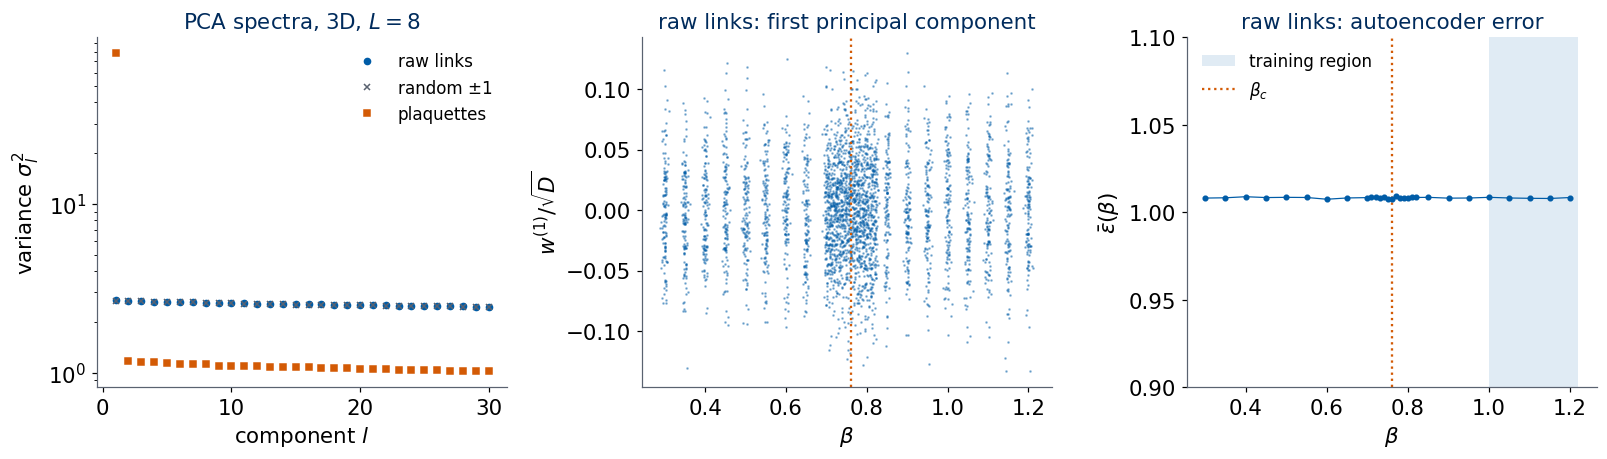

In [7]:
train, test = split_chains(d8)
F_links = d8["links"].reshape(n_b, d8["links"].shape[1], -1)                     # (29, 1024, 1536) int8 raw links
reg = B8 >= 1.0 - 1e-9
t0 = time.perf_counter()
model_raw, loss_raw = train_ae(F_links[reg][:, train].reshape(-1, F_links.shape[-1]))
eps_raw = error_curve(model_raw, F_links, test)                                    # (29, 512)
e_raw, de_raw = eps_raw.mean(1), sem(eps_raw, d8["chain"][test])
print(f"raw links, L = 8, trained on beta >= 1.0 ({int(reg.sum()) * int(train.sum())} configurations): final training loss {loss_raw:.4f}  "
      f"({time.perf_counter() - t0:.0f} s)")
print(f"mean reconstruction error over all couplings: min {e_raw.min():.4f}, max {e_raw.max():.4f}, spread (max - min) {e_raw.max() - e_raw.min():.4f}, "
      f"typical error bar {np.median(de_raw):.4f}")
NUMBERS["raw_ae"] = dict(e_min=round(float(e_raw.min()), 4), e_max=round(float(e_raw.max()), 4), loss=round(loss_raw, 4))
NUMBERS["pca_raw_top"] = [round(float(v), 3) for v in PCA_RES["raw links"]["ev"][:3]]
NUMBERS["pca_noise_top"] = [round(float(v), 3) for v in PCA_RES["random ±1"]["ev"][:3]]

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
k = np.arange(1, 31)
for name, col, mk in (("raw links", UJBlue, "o"), ("random ±1", UJGray, "x"), ("plaquettes", DSOrange, "s")):
    ax[0].plot(k, PCA_RES[name]["ev"][:30], mk, ms=4, color=col, label=name)
ax[0].set_yscale("log"); ax[0].set_xlabel("component $l$"); ax[0].set_ylabel(r"variance $\sigma_l^2$")
ax[0].set_title("PCA spectra, 3D, $L=8$"); ax[0].legend(frameon=False, fontsize=11)
P = PCA_RES["raw links"]
w1 = (X_links - P["mu"]) @ P["Vt"][0] / np.sqrt(X_links.shape[1])
ax[1].plot(beta_row + np.random.default_rng(1).normal(0, 0.004, beta_row.size), w1, ".", ms=1.5, alpha=0.4, color=UJBlue)
ax[1].axvline(BETA_C, color=DSOrange, ls=":", lw=1.5)
ax[1].set_xlabel(r"$\beta$"); ax[1].set_ylabel(r"$w^{(1)}/\sqrt{D}$"); ax[1].set_title("raw links: first principal component")
ax[2].errorbar(B8, e_raw, de_raw, fmt="o-", ms=3, lw=0.8, color=UJBlue)
ax[2].axvspan(1.0, 1.22, color=UJBlue, alpha=0.12, lw=0, label=r"training region")
ax[2].axvline(BETA_C, color=DSOrange, ls=":", lw=1.5, label=r"$\beta_c$")
ax[2].set_ylim(0.9, 1.1); ax[2].set_xlabel(r"$\beta$"); ax[2].set_ylabel(r"$\bar\varepsilon(\beta)$")
ax[2].set_title("raw links: autoencoder error"); ax[2].legend(frameon=False, fontsize=11)
fig.tight_layout(); savefig(fig, "gen_gauge_ml_raw.png"); plt.show()

All three panels say the same thing. The raw-link spectrum is the spectrum of coin flips; the first principal component is a random direction
whose projection has the same distribution at every $\beta$; and the autoencoder, even when trained on the most ordered data available, does not
learn to reconstruct anything: its error stays at $\varepsilon\approx1$ (slightly above, from fitting noise in the training set), flat across
the transition. The reason is the gauge redundancy. A configuration in a random gauge is a uniformly random element of its gauge orbit, and the orbit has
$2^{N-1}$ elements ($N=L^3$ sites) out of $2^{3N}$ link configurations. Even a perfectly ordered physical state, all $U_p=+1$, appears as $N-1$
random bits spread over the links, and no low-dimensional code can reconstruct those bits. Whatever distinguishes the phases is hidden in
products of at least four links around closed paths, which neither a linear method nor a small dense network finds by itself.

<hr/>
## 3. Plaquettes

### 3.1 Principal components of plaquettes

The plaquette $U_p$ is gauge invariant, so replacing the $3L^3$ links by the $3L^3$ plaquettes removes the gauge redundancy without losing any
local physical information. The PCA of Section 2.1 already showed that the plaquette spectrum has one dominant eigenvalue. We now look at its
eigenvector and at the projection of the data on it. If $\boldsymbol\lambda_1$ is close to the uniform vector $\mathbf u=(1,\dots,1)/\sqrt D$, the projection
is, up to an offset, the plaquette average: $w^{(1)}/\sqrt D\approx\bar U-\langle\bar U\rangle_{\rm all}$, which is minus the energy per plaquette.

plaquettes, L = 8: fraction of variance of PC1 = 0.1554, of PC2 = 0.00232;  sigma_1^2 / sigma_2^2 = 66.9
overlap of lambda_1 with the uniform vector: 0.9984;  correlation of w^(1) with the plaquette average: 0.99999


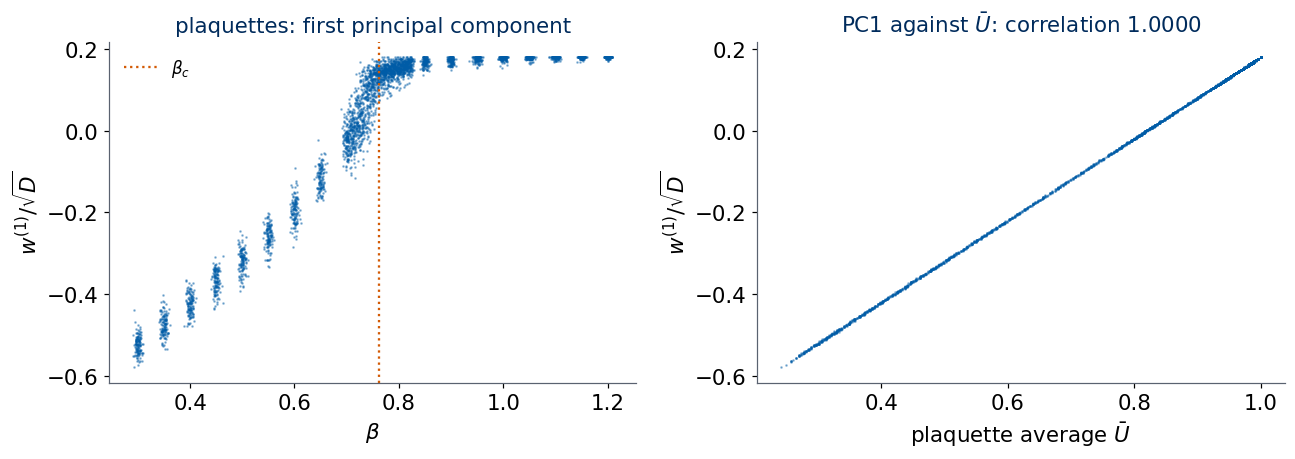

In [8]:
P = PCA_RES["plaquettes"]
ev_ratio = P["ev"] / P["ev"].sum()
lam1 = P["Vt"][0] * np.sign(P["Vt"][0].sum())                    # fix the sign so that lambda_1 points along +U
overlap_uniform = abs(lam1.sum()) / np.sqrt(len(lam1))
w1p = (X_plaq - P["mu"]) @ lam1 / np.sqrt(X_plaq.shape[1])
Ubar_rows = X_plaq.mean(1)
corr_pc1_U = np.corrcoef(w1p, Ubar_rows)[0, 1]
print(f"plaquettes, L = 8: fraction of variance of PC1 = {ev_ratio[0]:.4f}, of PC2 = {ev_ratio[1]:.5f};  "
      f"sigma_1^2 / sigma_2^2 = {P['ev'][0] / P['ev'][1]:.1f}")
print(f"overlap of lambda_1 with the uniform vector: {overlap_uniform:.4f};  correlation of w^(1) with the plaquette average: {corr_pc1_U:.5f}")
NUMBERS.update(pca_plaq_var1=round(float(ev_ratio[0]), 4), pca_plaq_var2=round(float(ev_ratio[1]), 5),
               pca_plaq_ratio=round(float(P["ev"][0] / P["ev"][1]), 1),
               pca_plaq_uniform=round(float(overlap_uniform), 4), pca_plaq_corrU=round(float(corr_pc1_U), 5))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
ax[0].plot(beta_row + np.random.default_rng(2).normal(0, 0.004, beta_row.size), w1p, ".", ms=1.5, alpha=0.4, color=UJBlue)
ax[0].axvline(BETA_C, color=DSOrange, ls=":", lw=1.5, label=r"$\beta_c$")
ax[0].set_xlabel(r"$\beta$"); ax[0].set_ylabel(r"$w^{(1)}/\sqrt{D}$"); ax[0].set_title("plaquettes: first principal component")
ax[0].legend(frameon=False, fontsize=11)
ax[1].plot(Ubar_rows, w1p, ".", ms=1.5, alpha=0.4, color=UJBlue)
ax[1].set_xlabel(r"plaquette average $\bar U$"); ax[1].set_ylabel(r"$w^{(1)}/\sqrt{D}$")
ax[1].set_title(f"PC1 against $\\bar U$: correlation {corr_pc1_U:.4f}")
fig.tight_layout(); savefig(fig, "gen_gauge_ml_plaq_pca.png"); plt.show()

The first eigenvalue is about $67$ times larger than the second. It accounts for $15.5\%$ of the total variance, because the remaining
$1535$ directions, each carrying a small amount of independent plaquette noise, add up to the rest; none of them stands out. The leading
direction $\boldsymbol\lambda_1$ is the uniform vector (overlap $0.998$), and the projection on it is the plaquette average with correlation $0.99999$. PCA has found the energy. That is the correct answer to the question PCA asks (which single linear
combination of the plaquettes varies most across the pooled data set), and it changes fastest near $\beta_c$, but it contains no information beyond the
energy: the remaining eigenvalues form a flat noise band. Section 4 asks whether something beyond the energy can be found.

### 3.2 Autoencoder anomaly detection in three dimensions

We now repeat the protocol of Labs 019 and 020 with the plaquettes as input. For every lattice size $L=6,8,10$ we train the dense autoencoder of
Section 2.2 on plaquette vectors of length $D=3L^3$ from one end of the coupling range and evaluate the mean reconstruction error over the whole range.
Two training regions are used, one in each phase:

| training region | couplings | physical state |
|---|---|---|
| deconfined | $\beta\ge1.0$ (5 couplings) | almost all plaquettes $+1$, rare small flux loops |
| confined | $\beta\le0.45$ (4 couplings) | plaquettes nearly independent, $\langle U_p\rangle\approx\tanh\beta$ |

If the reconstruction error behaved like the error of Lab 019 for the Ising model, it would change sharply at a coupling that approaches
$\beta_c$ as $L$ grows. We read off the position of the steepest change, $\beta^\ast$, as the midpoint of the grid interval with the largest
$|\Delta\bar\varepsilon/\Delta\beta|$, and estimate its uncertainty by a jackknife over the eight evaluation chains (the estimate is recomputed
with one chain left out at a time).

In [9]:
REGIMES = {3: {"deconfined": lambda b: b >= 1.0 - 1e-9, "confined": lambda b: b <= 0.45 + 1e-9},
           2: {"large beta": lambda b: b >= 2.0 - 1e-9, "small beta": lambda b: b <= 0.5 + 1e-9}}

def steepest_jackknife(beta, eps, chain):
    # beta* from the mean curve, and its jackknife error over chains;  eps: (n_beta, n_test), chain: (n_test,)
    cm = chain_means(eps, chain)                                        # (n_beta, n_chains)
    b0 = steepest(beta, cm.mean(1))[0]
    n = cm.shape[1]
    jk = np.array([steepest(beta, np.delete(cm, r, axis=1).mean(1))[0] for r in range(n)])
    return b0, np.sqrt((n - 1) * jk.var())

AE = {}
t0 = time.perf_counter()
for key in ((3, 6), (3, 8), (3, 10), (2, 16), (2, 32)):
    dset = ds[key]; B = dset["beta"]
    train, test = split_chains(dset)
    F = dset["plaq"]
    for r_name, r_fn in REGIMES[key[0]].items():
        t1 = time.perf_counter()
        reg = r_fn(B)
        model, loss = train_ae(F[reg][:, train].reshape(-1, F.shape[-1]))
        eps = error_curve(model, F, test)
        e, de = eps.mean(1), sem(eps, dset["chain"][test])
        b_star, db_star = steepest_jackknife(B, eps, dset["chain"][test])
        e_norm = (e - e[-1]) / (e[0] - e[-1])                           # 1 at the smallest beta, 0 at the largest
        AE[(key, r_name)] = dict(eps=eps, e=e, de=de, loss=loss, b_star=b_star, db_star=db_star, e_norm=e_norm,
                                 slope=steepest(B, e_norm)[1], corrU=np.corrcoef(e, dset["U"])[0, 1])
        print(f"d = {key[0]}, L = {key[1]:2d}, trained on {r_name:10s}: loss {loss:.4f}, beta* = {b_star:.3f} +- {db_star:.3f}, "
              f"corr(eps, <U_p>) = {AE[(key, r_name)]['corrU']:+.5f}  ({time.perf_counter() - t1:.0f} s)")
print(f"all autoencoders: {time.perf_counter() - t0:.0f} s")

d = 3, L =  6, trained on deconfined: loss 0.0029, beta* = 0.715 +- 0.000, corr(eps, <U_p>) = -0.99911  (3 s)


d = 3, L =  6, trained on confined  : loss 0.8146, beta* = 0.715 +- 0.026, corr(eps, <U_p>) = -0.99590  (3 s)


d = 3, L =  8, trained on deconfined: loss 0.0034, beta* = 0.735 +- 0.009, corr(eps, <U_p>) = -0.99886  (3 s)


d = 3, L =  8, trained on confined  : loss 0.8397, beta* = 0.735 +- 0.009, corr(eps, <U_p>) = -0.99467  (3 s)


d = 3, L = 10, trained on deconfined: loss 0.0035, beta* = 0.745 +- 0.000, corr(eps, <U_p>) = -0.99966  (4 s)


d = 3, L = 10, trained on confined  : loss 0.8568, beta* = 0.745 +- 0.000, corr(eps, <U_p>) = -0.99488  (3 s)


d = 2, L = 16, trained on large beta: loss 0.0472, beta* = 0.450 +- 0.207, corr(eps, <U_p>) = -0.99080  (2 s)


d = 2, L = 16, trained on small beta: loss 0.8068, beta* = 0.550 +- 0.000, corr(eps, <U_p>) = -0.98789  (2 s)


d = 2, L = 32, trained on large beta: loss 0.0499, beta* = 0.650 +- 0.175, corr(eps, <U_p>) = -0.98954  (2 s)


d = 2, L = 32, trained on small beta: loss 0.8561, beta* = 0.650 +- 0.245, corr(eps, <U_p>) = -0.98623  (2 s)
all autoencoders: 28 s


Before reading the curves, recall what the two models can learn. A model trained on deconfined plaquettes sees vectors that are $+1$ almost everywhere,
so its best reconstruction is close to $\hat U_p=+1$ for every plaquette; the error of a configuration is then
$\varepsilon\approx\frac1{N_p}\sum_p(U_p-1)^2=2(1-\bar U)$, four times the fraction of frustrated plaquettes. A model trained on confined data sees
nearly independent plaquettes with mean $m\approx\tanh\beta$; its best reconstruction is close to the constant $m$, and
$\varepsilon\approx1-2m\bar U+m^2$. In both cases the error is close to an affine function of the plaquette average, which is the energy. The figure tests this.

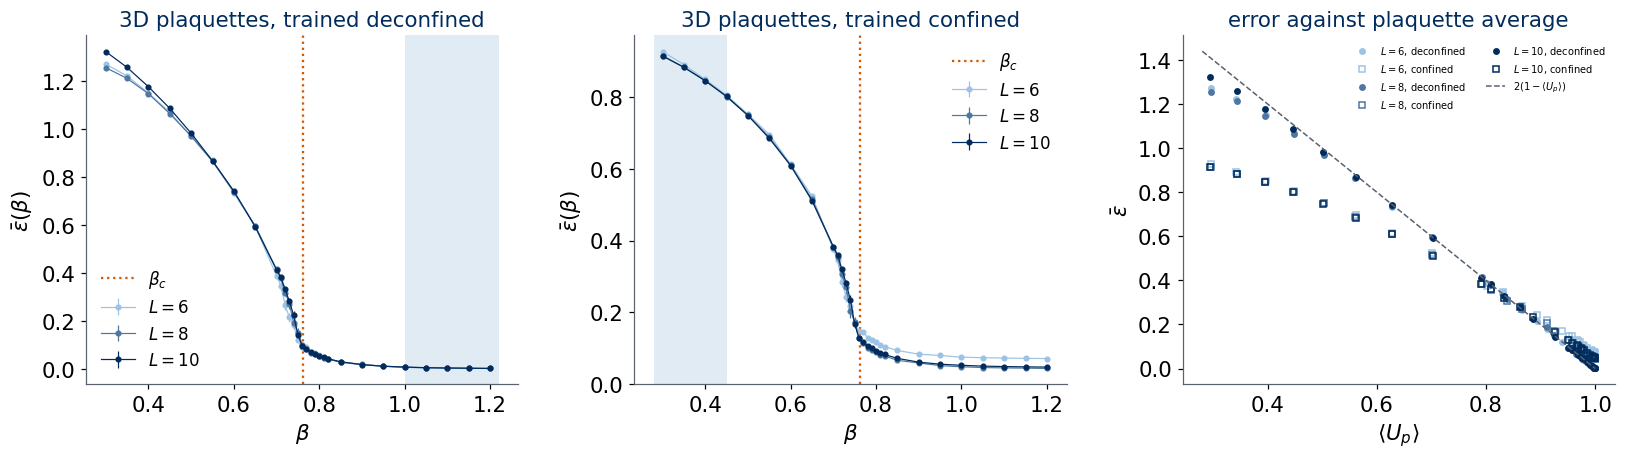

deconfined L =  6: eps ~ -1.886 <U_p> +1.894, max deviation from the line 0.0647 (range of eps 1.271)
deconfined L =  8: eps ~ -1.876 <U_p> +1.885, max deviation from the line 0.0737 (range of eps 1.256)
deconfined L = 10: eps ~ -1.932 <U_p> +1.936, max deviation from the line 0.0431 (range of eps 1.323)
confined   L =  6: eps ~ -1.284 <U_p> +1.374, max deviation from the line 0.0670 (range of eps 0.856)
confined   L =  8: eps ~ -1.322 <U_p> +1.387, max deviation from the line 0.0801 (range of eps 0.872)
confined   L = 10: eps ~ -1.315 <U_p> +1.382, max deviation from the line 0.0797 (range of eps 0.867)


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
for j, L in enumerate((6, 8, 10)):
    B = ds[(3, L)]["beta"]; col = blues(j / 2)
    for a, r_name in zip(ax[:2], ("deconfined", "confined")):
        res = AE[((3, L), r_name)]
        a.errorbar(B, res["e"], res["de"], fmt="o-", ms=3, lw=0.8, color=col, label=f"$L={L}$")
    ax[2].plot(ds[(3, L)]["U"], AE[((3, L), "deconfined")]["e"], "o", ms=3.5, color=col, label=f"$L={L}$, deconfined")
    ax[2].plot(ds[(3, L)]["U"], AE[((3, L), "confined")]["e"], "s", ms=3.5, mfc="none", color=col, label=f"$L={L}$, confined")
uu = np.linspace(0.28, 1.0, 50)
ax[2].plot(uu, 2 * (1 - uu), color=UJGray, ls="--", lw=1, label=r"$2(1-\langle U_p\rangle)$")
for a, r_name, span in ((ax[0], "deconfined", (1.0, 1.22)), (ax[1], "confined", (0.28, 0.45))):
    a.axvspan(*span, color=UJBlue, alpha=0.12, lw=0)
    a.axvline(BETA_C, color=DSOrange, ls=":", lw=1.5, label=r"$\beta_c$")
    a.set_xlabel(r"$\beta$"); a.set_ylabel(r"$\bar\varepsilon(\beta)$"); a.set_title(f"3D plaquettes, trained {r_name}")
    a.legend(frameon=False, fontsize=11)
ax[2].set_xlabel(r"$\langle U_p\rangle$"); ax[2].set_ylabel(r"$\bar\varepsilon$"); ax[2].set_title("error against plaquette average")
ax[2].legend(frameon=False, fontsize=6.5, ncol=2)
fig.tight_layout(); savefig(fig, "gen_gauge_ml_ae_3d.png"); plt.show()

for r_name in ("deconfined", "confined"):
    for L in (6, 8, 10):
        res, dset = AE[((3, L), r_name)], ds[(3, L)]
        a1, a0 = np.polyfit(dset["U"], res["e"], 1)
        resid = res["e"] - (a1 * dset["U"] + a0)
        res["affine"] = (a1, a0, np.abs(resid).max())
        print(f"{r_name:10s} L = {L:2d}: eps ~ {a1:+.3f} <U_p> {a0:+.3f}, max deviation from the line {np.abs(resid).max():.4f} "
              f"(range of eps {res['e'].max() - res['e'].min():.3f})")

Both training choices give a reconstruction error that falls steeply between $\beta\approx0.6$ and $\beta\approx0.8$, the region of the
transition. Plotted against $\langle U_p\rangle$ (right panel), however, the points of all three lattice sizes collapse onto one curve per training
region: for the deconfined models a straight line close to $2(1-\langle U_p\rangle)$, for the confined models a smooth curve that bends only at
small $\langle U_p\rangle$, the same for $L=6,8,10$. The linear fits printed above have slopes close to $-1.9$ and $-1.3$. The detector measures the energy. Everything it reports about the transition is therefore what the energy reports: the steepest change of
$\bar\varepsilon$ is where $\langle U_p\rangle$ rises fastest, that is, close to the maximum of $c/\beta^2$.

This does not make the detector useless. A sharp rise of the energy is a real signature of the transition, and the detector finds it without being told
that the energy matters. But it would find the same signature at a smooth crossover. To tell the two apart we have to look at the dependence on the lattice size,
and compare with a model that has no transition.

### 3.3 Two dimensions as a control

The 2D Ising gauge theory has $\langle U_p\rangle=\tanh\beta$ exactly, independent plaquettes and no phase transition at any $T>0$. We run the
same pipeline on $L=16$ and $L=32$, with training regions at the two ends of its coupling range, $\beta\ge2.0$ and $\beta\le0.5$. Any curve has a
point of steepest change, so the 2D detector will also return a $\beta^\ast$. The question is how $\beta^\ast$ and the steepness behave with $L$.

To compare the steepness of curves with different ranges we normalise each curve to run from $1$ at the smallest to $0$ at the largest coupling,
$\tilde\varepsilon(\beta)=\big(\bar\varepsilon(\beta)-\bar\varepsilon(\beta_{\max})\big)/\big(\bar\varepsilon(\beta_{\min})-\bar\varepsilon(\beta_{\max})\big)$,
and plot $-\Delta\tilde\varepsilon/\Delta\beta$ on the grid. The third panel collects all estimates of $\beta^\ast$ in 3D against $1/L$ together with the
specific-heat peak and $\beta_c$.

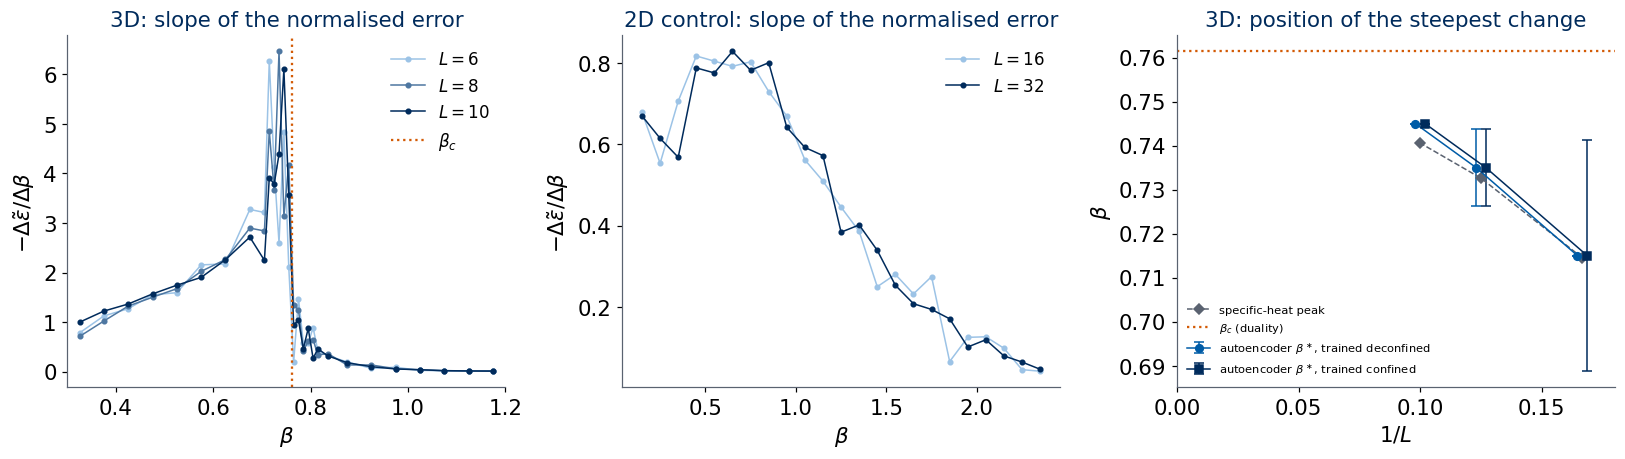

  d   L   regime        beta*            max slope of normalised error     steepest <U_p>   specific-heat peak
  3   6   deconfined   0.715 +- 0.000        6.27                          0.715           0.7145
  3   6   confined     0.715 +- 0.026        7.04                          0.715           0.7145
  3   8   deconfined   0.735 +- 0.009        6.46                          0.735           0.7326
  3   8   confined     0.735 +- 0.009        7.63                          0.735           0.7326
  3  10   deconfined   0.745 +- 0.000        6.10                          0.745           0.7406
  3  10   confined     0.745 +- 0.000        7.65                          0.745           0.7406
  2  16   large beta   0.450 +- 0.207        0.82                          0.150             -   
  2  16   small beta   0.550 +- 0.000        0.85                          0.150             -   
  2  32   large beta   0.650 +- 0.175        0.83                          0.150             -   
  2  32

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
for panel, keys in ((0, ((3, 6), (3, 8), (3, 10))), (1, ((2, 16), (2, 32)))):
    r_name = "deconfined" if panel == 0 else "large beta"
    for j, key in enumerate(keys):
        B = ds[key]["beta"]; res = AE[(key, r_name)]
        bm = 0.5 * (B[1:] + B[:-1]); sl = -np.diff(res["e_norm"]) / np.diff(B)
        col = blues(j / max(1, len(keys) - 1))
        ax[panel].plot(bm, sl, "o-", ms=3, lw=1, color=col, label=f"$L={key[1]}$")
ax[0].axvline(BETA_C, color=DSOrange, ls=":", lw=1.5, label=r"$\beta_c$"); ax[0].set_xlim(0.3, 1.2)
ax[0].set_title("3D: slope of the normalised error"); ax[1].set_title("2D control: slope of the normalised error")
bb = np.linspace(0.1, 2.4, 200)
for a in ax[:2]:
    a.set_xlabel(r"$\beta$"); a.set_ylabel(r"$-\Delta\tilde\varepsilon/\Delta\beta$"); a.legend(frameon=False, fontsize=11)
invL = np.array([1 / 6, 1 / 8, 1 / 10])
for r_name, mk, col in (("deconfined", "o", UJBlue), ("confined", "s", UJNavy)):
    bs = np.array([AE[((3, L), r_name)]["b_star"] for L in (6, 8, 10)])
    dbs = np.array([AE[((3, L), r_name)]["db_star"] for L in (6, 8, 10)])
    off = -0.002 if r_name == "deconfined" else 0.002            # small horizontal offset: the two regimes give identical values
    ax[2].errorbar(invL + off, bs, dbs, fmt=mk + "-", ms=5, lw=1, color=col, capsize=3, label=f"autoencoder $\\beta^\\ast$, trained {r_name}")
ax[2].plot(invL, [ds[(3, L)]["c_peak"] for L in (6, 8, 10)], "D--", ms=5, lw=1, color=UJGray, label="specific-heat peak")
ax[2].axhline(BETA_C, color=DSOrange, ls=":", lw=1.5, label=r"$\beta_c$ (duality)")
ax[2].set_xlim(0, 0.18); ax[2].set_xlabel("$1/L$"); ax[2].set_ylabel(r"$\beta$"); ax[2].set_title("3D: position of the steepest change")
ax[2].legend(frameon=False, fontsize=7.5, loc="lower left")
fig.tight_layout(); savefig(fig, "gen_gauge_ml_fss.png"); plt.show()

print("  d   L   regime        beta*            max slope of normalised error     steepest <U_p>   specific-heat peak")
for key in ((3, 6), (3, 8), (3, 10), (2, 16), (2, 32)):
    for r_name in REGIMES[key[0]]:
        res = AE[(key, r_name)]
        cp = f"{ds[key]['c_peak']:.4f}" if key[0] == 3 else "  -   "
        print(f"  {key[0]}  {key[1]:2d}   {r_name:11s}  {res['b_star']:.3f} +- {res['db_star']:.3f}      {res['slope']:6.2f}"
              f"                          {ds[key]['U_steep']:.3f}           {cp}")
NUMBERS["ae"] = {f"{key[0]}d_L{key[1]}_{r_name}": dict(b_star=round(float(AE[(key, r_name)]["b_star"]), 3),
                                                        db_star=round(float(AE[(key, r_name)]["db_star"]), 3),
                                                        slope=round(float(AE[(key, r_name)]["slope"]), 2),
                                                        corrU=round(float(AE[(key, r_name)]["corrU"]), 5),
                                                        loss=round(float(AE[(key, r_name)]["loss"]), 4))
                 for key in ((3, 6), (3, 8), (3, 10), (2, 16), (2, 32)) for r_name in REGIMES[key[0]]}
NUMBERS["U_steep"] = {f"{k[0]}d_L{k[1]}": round(float(ds[k]["U_steep"]), 3) for k in ds}
NUMBERS["ae_affine_maxdev"] = {f"{r}_L{L}": round(float(AE[((3, L), r)]["affine"][2]), 4) for r in ("deconfined", "confined") for L in (6, 8, 10)}

The comparison is now possible. In 3D the steepest change of the reconstruction error lies at $\beta^\ast=0.715$, $0.735$ and $0.745$ for $L=6,8,10$,
for both training regions, which is exactly the grid interval in which $\langle U_p\rangle$ rises fastest and within $0.005$ of the specific-heat peak
(table above). It lies below $\beta_c=0.761$ and moves towards it as $L$ grows. The jackknife spread is below the grid step except for the smallest lattice
trained on confined data. In 2D the slope curves of $L=16$ and $L=32$ lie on top of each other: the error has a broad region of steepest descent between
$\beta\approx0.4$ and $\beta\approx0.9$, whose position is so poorly defined that the jackknife errors of $\beta^\ast$ reach $0.2$, and which neither moves nor
sharpens with the size, as expected for a smooth crossover. (The 2D error is not exactly affine in $\langle U_p\rangle=\tanh\beta$, whose steepest rise is at the
smallest coupling; the nonlinearity of the trained network shifts the broad maximum of the slope.) The 2D curve would have produced a "transition" at
$\beta^\ast$ had we looked at one lattice size only; the systematic size dependence is what tells the two cases apart.

Two limits of this result should be stated. First, the detector does not see more than the energy, so it inherits the finite-size behaviour of the energy:
its $\beta^\ast$ approaches $\beta_c$ from below like the specific-heat peak. The maximal slope of the normalised error does not grow
systematically with $L$ in our data ($6.27$, $6.46$, $6.10$ for the deconfined training region, $7.04$, $7.63$, $7.65$ for the confined one): the sharpening is
not resolved. This is the same limitation Lab 031 met for the specific heat, whose peak heights for $L=8$ and $L=10$ are not resolved from each other with
this statistics, made worse here because the slopes are finite differences on a grid of step $0.01$. Second, the 3D transition is continuous, and its energy is
continuous at $\beta_c$; the steep rise is a rounded version of a weak singularity (the specific heat of the 3D Ising universality class). A detector of the energy
cannot be sharper than the energy.

<hr/>
## 4. Wilson loops as features

Plaquettes are $1\times1$ Wilson loops. The physical distinction between the phases, area law against perimeter law, concerns how loops of
different sizes are related to one another, so it is natural to give the methods loops of several sizes. For every configuration we have the
averages $\bar W(R,R)$ for $R=1,2,3,4$ (and the rectangle $1\times2$ needed below), computed in Section 1.

### 4.1 Principal components of loop averages

We first try the generic route: the per-configuration feature vector $\mathbf y=(\bar W(1,1),\bar W(2,2),\bar W(3,3),\bar W(4,4))$, pooled over all couplings
of the 3D lattice with $L=10$, standardised to zero mean and unit variance per feature, and analysed by PCA (again in JAX and checked against scikit-learn).

In [12]:
d10 = ds[(3, 10)]; B10 = d10["beta"]
cols = [IDX[(R, R)] for R in (1, 2, 3, 4)]
Wf = d10["loops"][..., cols].reshape(-1, 4)                                      # (29696, 4)
Zf = ((Wf - Wf.mean(0)) / Wf.std(0)).astype(np.float32)
mu_w, ev_w, Vt_w = (np.asarray(a) for a in pca(jnp.asarray(Zf)))
rel, ovl = compare_with_sklearn(Zf, ev_w, Vt_w, k=4)
print(f"scikit-learn: max relative deviation of sigma_l^2 {rel:.1e}, |lambda_l . lambda_l'| = {np.round(ovl, 4)}")
assert rel < 1e-3 and np.all(ovl > 0.999)
var_w = ev_w / ev_w.sum()
zw = (Zf - mu_w) @ Vt_w[:2].T
corr_w = np.corrcoef(zw[:, 0], d10["Ubar"].ravel())[0, 1]
print(f"fractions of variance: {np.round(var_w, 4)};  lambda_1 = {np.round(Vt_w[0] * np.sign(Vt_w[0].sum()), 3)};  lambda_2 = {np.round(Vt_w[1], 3)}")
print(f"|correlation| of PC1 with the plaquette average: {abs(corr_w):.4f}")
NUMBERS.update(loop_pca_var=[round(float(v), 4) for v in var_w], loop_pca_corrU=round(float(abs(corr_w)), 4))

scikit-learn: max relative deviation of sigma_l^2 5.2e-07, |lambda_l . lambda_l'| = [1. 1. 1. 1.]
fractions of variance: [9.552e-01 4.270e-02 1.900e-03 2.000e-04];  lambda_1 = [0.487 0.509 0.507 0.496];  lambda_2 = [-0.738 -0.166  0.315  0.573]
|correlation| of PC1 with the plaquette average: 0.9515


The first component carries $95.5\%$ of the variance and weights the four loops nearly equally: all loop averages rise together when $\beta$ grows, and the common trend is essentially the energy (correlation $0.95$ with $\bar U$; the large
loops add some curvature to it). The second component, a contrast between small and large
loops, carries a few percent of the variance. It is where the area–perimeter information could be, but as a linear combination of loop *values* it
mixes that information with the trivial nonlinearity $W(R,R)\approx\langle U_p\rangle^{R^2}$, which is present in 2D as well, where nothing happens. Linear methods
applied to the loop values are the wrong tool: the distinction between the phases is a statement about how $\ln W$ scales with the size of the loop.

### 4.2 Loop-shape exponent and Creutz ratio

The physics tells us which combination to build. If $-\ln W(R,R)\propto R^{a}$, then $a=2$ for an area law (confinement) and $a=1$ for a perimeter law
(deconfinement). Comparing the two smallest square loops gives the **loop-shape exponent**
$$
a(\beta)=\log_2\frac{\ln W(2,2)}{\ln W(1,1)} ,
$$
which equals $2$ exactly when the plaquettes are independent, $W(R,R)=\langle U_p\rangle^{R^2}$, as in 2D. The second combination is the Creutz ratio of Lab 031,
$$
\chi(2,2)=-\ln\frac{W(2,2)\,W(1,1)}{W(2,1)^2},
$$
in which the perimeter and constant terms of $\ln W$ cancel, so that $\chi=\sigma_s$ for $W=e^{-\sigma_sRT-2\mu(R+T)-c_0}$; it estimates the string tension $\sigma_s$,
positive in the confined phase and zero in the deconfined phase. In 2D, $\chi(2,2)=-\ln\tanh\beta>0$ at every $\beta$. Both quantities are
computed from the thermal averages $W(R,T)$ at each coupling, with jackknife errors over the 16 chains.

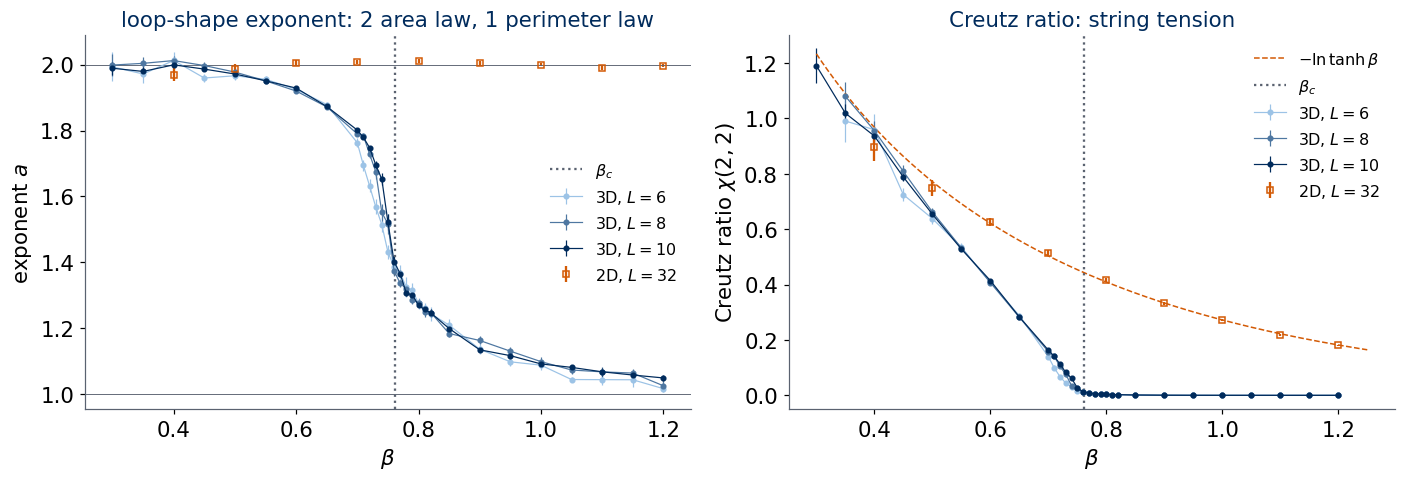

2D, L = 32: a = 1.998, spread over 21 couplings 1.970 .. 2.012
3D, L =  6: a(0.60) = 1.925,  a = 1.5 at beta = 0.742,  a(0.90) = 1.136;   chi(2,2): 0.408 at 0.60, 0.0110 at 0.76, 0.0005 at 0.90
3D, L =  8: a(0.60) = 1.920,  a = 1.5 at beta = 0.751,  a(0.90) = 1.162;   chi(2,2): 0.407 at 0.60, 0.0104 at 0.76, 0.0006 at 0.90
3D, L = 10: a(0.60) = 1.929,  a = 1.5 at beta = 0.752,  a(0.90) = 1.134;   chi(2,2): 0.415 at 0.60, 0.0125 at 0.76, 0.0004 at 0.90


In [13]:
def loop_observables(dset):
    # a(beta), chi(2,2)(beta) with jackknife errors over chains;  NaN where a loop average is not positive
    W, ch = dset["loops"], dset["chain"]
    cm = np.stack([W[:, ch == r].mean(1) for r in np.unique(ch)], 1)          # (n_beta, n_chains, n_loops)
    def obs(Wm):
        with np.errstate(invalid="ignore", divide="ignore"):
            a = np.log2(np.log(Wm[..., IDX[(2, 2)]]) / np.log(Wm[..., IDX[(1, 1)]]))
            chi = -np.log(Wm[..., IDX[(2, 2)]] * Wm[..., IDX[(1, 1)]] / Wm[..., IDX[(1, 2)]] ** 2)
        return a, chi
    a0, chi0 = obs(cm.mean(1))
    n = cm.shape[1]
    jk = [obs(np.delete(cm, r, axis=1).mean(1)) for r in range(n)]
    da = np.sqrt((n - 1) * np.var([j[0] for j in jk], axis=0)); dchi = np.sqrt((n - 1) * np.var([j[1] for j in jk], axis=0))
    return a0, da, chi0, dchi

def crossing(beta, y, level):
    # first beta where y falls below level, by linear interpolation between grid points
    k = int(np.argmax(y < level))
    return beta[k - 1] + (level - y[k - 1]) * (beta[k] - beta[k - 1]) / (y[k] - y[k - 1])

LO = {key: loop_observables(ds[key]) for key in ds}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for j, L in enumerate((6, 8, 10)):
    B = ds[(3, L)]["beta"]; a, da, chi, dchi = LO[(3, L)]; ok = np.isfinite(a) & (da < 0.2)
    ax[0].errorbar(B[ok], a[ok], da[ok], fmt="o-", ms=3, lw=0.8, color=blues(j / 2), label=f"3D, $L={L}$")
    okc = np.isfinite(chi) & (dchi < 0.1)
    ax[1].errorbar(B[okc], chi[okc], dchi[okc], fmt="o-", ms=3, lw=0.8, color=blues(j / 2), label=f"3D, $L={L}$")
B2 = ds[(2, 32)]["beta"]; a2, da2, chi2, dchi2 = LO[(2, 32)]
ok2 = np.isfinite(a2) & (da2 < 0.05) & (B2 <= 1.25)
ax[0].errorbar(B2[ok2], a2[ok2], da2[ok2], fmt="s", ms=4, mfc="none", color=DSOrange, label="2D, $L=32$")
okc2 = np.isfinite(chi2) & (dchi2 < 0.1) & (B2 <= 1.25)
ax[1].errorbar(B2[okc2], chi2[okc2], dchi2[okc2], fmt="s", ms=4, mfc="none", color=DSOrange, label="2D, $L=32$")
bb = np.linspace(0.3, 1.25, 200); ax[1].plot(bb, -np.log(np.tanh(bb)), color=DSOrange, lw=1, ls="--", label=r"$-\ln\tanh\beta$")
for a_ in ax:
    a_.axvline(BETA_C, color=UJGray, ls=":", lw=1.5, label=r"$\beta_c$"); a_.set_xlabel(r"$\beta$"); a_.legend(frameon=False, fontsize=10.5)
ax[0].axhline(2, color=UJGray, lw=0.6); ax[0].axhline(1, color=UJGray, lw=0.6)
ax[0].set_ylabel(r"exponent $a$"); ax[0].set_title("loop-shape exponent: 2 area law, 1 perimeter law")
ax[1].set_ylabel(r"Creutz ratio $\chi(2,2)$"); ax[1].set_ylim(-0.05, 1.3); ax[1].set_title("Creutz ratio: string tension")
fig.tight_layout(); savefig(fig, "gen_gauge_ml_loops.png"); plt.show()

a2_valid = a2[np.isfinite(a2) & (da2 < 0.05)]
print(f"2D, L = 32: a = {a2_valid.mean():.3f}, spread over {a2_valid.size} couplings {a2_valid.min():.3f} .. {a2_valid.max():.3f}")
NUMBERS["loop_a_2d"] = [round(float(a2_valid.mean()), 3), round(float(a2_valid.min()), 3), round(float(a2_valid.max()), 3)]
NUMBERS["loop_a_cross"] = {}
for L in (6, 8, 10):
    B = ds[(3, L)]["beta"]; a, da, chi, dchi = LO[(3, L)]
    m = np.isfinite(a) & (B >= 0.6)
    bx = crossing(B[m], a[m], 1.5)
    i76, i90, i60 = (int(np.argmin(np.abs(B - v))) for v in (0.76, 0.90, 0.60))
    NUMBERS["loop_a_cross"][str(L)] = round(float(bx), 3)
    print(f"3D, L = {L:2d}: a(0.60) = {a[i60]:.3f},  a = 1.5 at beta = {bx:.3f},  a(0.90) = {a[i90]:.3f};   "
          f"chi(2,2): {chi[i60]:.3f} at 0.60, {chi[i76]:.4f} at 0.76, {chi[i90]:.4f} at 0.90")
    NUMBERS[f"chi22_L{L}"] = dict(b060=round(float(chi[i60]), 3), b076=round(float(chi[i76]), 4), b090=round(float(chi[i90]), 4))
    NUMBERS[f"a_L{L}"] = dict(b060=round(float(a[i60]), 3), b090=round(float(a[i90]), 3))

These two plots show what the reconstruction error could not. In 2D the loop-shape exponent is $2$ at every coupling, within its error bars: the area law
holds at all temperatures, there is one phase, and the plaquettes are independent. In 3D the exponent starts at $2$ at small $\beta$ and drops towards $1$ above the transition;
it passes $a=1.5$ close to $\beta_c$ for all three lattice sizes (printed above). The Creutz ratio tells the same story more directly: in 2D it follows $-\ln\tanh\beta$
and never vanishes, while in 3D it falls from a clearly positive string tension in the confined phase to values compatible with zero above $\beta_c$.

The price is that these combinations were not discovered by an unsupervised method; they encode what we know about confinement. With loops up to $2\times2$ the
exponent and the Creutz ratio probe distances of one or two lattice spacings, so near $\beta_c$, where the correlation length exceeds these distances, they
change smoothly rather than jump, and their crossing points are not finite-size estimates of $\beta_c$ in the sense of a scaling analysis. What they provide
is a qualitative distinction that the energy alone cannot: the same smooth rise of $\langle U_p\rangle$ in 2D and 3D goes together with an area law in one case and
a change from area to perimeter law in the other.

<hr/>
## 5. Summary

We can now put the results side by side.

| input | method | result | compared with the known physics |
|---|---|---|---|
| raw links (random gauge) | PCA | spectrum of random $\pm1$ entries; PC1 independent of $\beta$ | Elitzur: every correlation of fewer than four links vanishes |
| raw links (random gauge) | autoencoder | $\bar\varepsilon\approx1$, flat across $\beta_c$ | gauge orbits of $2^{N-1}$ configurations cannot be compressed |
| plaquettes | PCA | PC1 = uniform vector, projection = $\bar U$ (energy) | correct, but nothing beyond the energy |
| plaquettes, 3D | autoencoder | steep change just below $\beta_c$, moving towards $\beta_c$ with $L$ | $\bar\varepsilon$ affine in $\langle U_p\rangle$: follows the specific-heat peak |
| plaquettes, 2D | autoencoder | same shape, no shift and no sharpening with $L$ | no transition: smooth crossover |
| Wilson loops | PCA | PC1 = energy again | linear in loop values: wrong representation |
| Wilson loops | exponent $a$, Creutz ratio $\chi$ | 2D: area law everywhere; 3D: area → perimeter law near $\beta_c$ | the confinement–deconfinement transition, but built from physics knowledge |

The result of Carrasquilla and Melko fits into this picture. Their task was supervised and easier than ours: distinguish 2D ground states (all $U_p=+1$) from
infinite-temperature configurations (independent random links). A fully connected network on raw links did not exceed chance level, for the reason we found in Section 2:
in a random gauge a single link and any pair of links carry no information. A convolutional network with $2\times2$ filters succeeded, because one filter covers
the four links of a plaquette and can compute $U_p$; their analysis showed that the network relied on the local plaquette constraint, which is the energy. That is precisely
what our unsupervised detectors find once the plaquettes are given to them: the energy, and through it the location of the steep change.

For the Ising gauge theory, then, the unsupervised methods of this lecture locate the transition region only after the gauge redundancy has been removed
by gauge-invariant variables that we chose, and even then they report the energy. Telling a genuine transition from a crossover required the size dependence, and recognising
*what* changes at $\beta_c$ (the loss of the area law) required observables built from the physics of Wilson loops.

<hr/>
## Exercises

1. Replace the dense autoencoder on plaquettes by a convolutional one with periodic padding (as in Lab 020) acting on the $(3,L,L,L)$ plaquette array.
   Does its reconstruction error still collapse onto a function of $\langle U_p\rangle$?
2. Train the autoencoder on plaquettes with $0.70\le\beta\le0.74$ only, just below $\beta_c$. Where does the steepest change of the error appear now (compare
   with Lab 019, where a training window in the middle of the transition put the jump at the edge of the window)?
3. Use the loop-shape exponent with larger loops, $a_3=\log_3[\ln W(3,3)/\ln W(1,1)]$, computed from the features already stored in `ds[key]["loops"]`.
   Compare its crossover with that of $a$ and explain the difference in terms of the size of the loops and the correlation length.

<hr/>
## References

* F. J. Wegner, *Duality in generalized Ising models and phase transitions without local order parameters*, J. Math. Phys. **12**, 2259 (1971), [doi:10.1063/1.1665530](https://doi.org/10.1063/1.1665530).
* K. G. Wilson, *Confinement of quarks*, Phys. Rev. D **10**, 2445 (1974), [doi:10.1103/PhysRevD.10.2445](https://doi.org/10.1103/PhysRevD.10.2445).
* S. Elitzur, *Impossibility of spontaneously breaking local symmetries*, Phys. Rev. D **12**, 3978 (1975), [doi:10.1103/PhysRevD.12.3978](https://doi.org/10.1103/PhysRevD.12.3978).
* M. Creutz, *Monte Carlo study of quantized SU(2) gauge theory*, Phys. Rev. D **21**, 2308 (1980), [doi:10.1103/PhysRevD.21.2308](https://doi.org/10.1103/PhysRevD.21.2308) (the Creutz ratio).
* J. B. Kogut, *An introduction to lattice gauge theory and spin systems*, Rev. Mod. Phys. **51**, 659 (1979), [doi:10.1103/RevModPhys.51.659](https://doi.org/10.1103/RevModPhys.51.659).
* A. M. Ferrenberg, J. Xu, D. P. Landau, *Pushing the limits of Monte Carlo simulations for the three-dimensional Ising model*, Phys. Rev. E **97**, 043301 (2018),
  [doi:10.1103/PhysRevE.97.043301](https://doi.org/10.1103/PhysRevE.97.043301), [arXiv:1806.03558](https://arxiv.org/abs/1806.03558).
* J. Carrasquilla, R. G. Melko, *Machine learning phases of matter*, Nature Physics **13**, 431 (2017), [doi:10.1038/nphys4035](https://doi.org/10.1038/nphys4035),
  [arXiv:1605.01735](https://arxiv.org/abs/1605.01735).
* K. Kottmann, P. Huembeli, M. Lewenstein, A. Acín, *Unsupervised phase discovery with deep anomaly detection*, Phys. Rev. Lett. **125**, 170603 (2020),
  [doi:10.1103/PhysRevLett.125.170603](https://doi.org/10.1103/PhysRevLett.125.170603), [arXiv:2003.09905](https://arxiv.org/abs/2003.09905).
* L. Wang, *Discovering phase transitions with unsupervised learning*, Phys. Rev. B **94**, 195105 (2016), [doi:10.1103/PhysRevB.94.195105](https://doi.org/10.1103/PhysRevB.94.195105).